In [35]:

import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd

torch.manual_seed(42)

# 1. Define names and sports
first_names = ["Michael", "Lionel", "Roger", "Serena"]
last_names = ["Jordan", "Phelps", "Messi", "Federer"]

sport_data = {
    ("Michael", "Jordan"): "Basketball",
    ("Michael", "Phelps"): "Swimming",
    ("Michael", "Messi"): "Football",
    ("Michael", "Federer"): "Tennis",
    ("Lionel", "Jordan"): "Football",
    ("Lionel", "Phelps"): "Swimming",
    ("Lionel", "Messi"): "Football",
    ("Lionel", "Federer"): "Tennis",
    ("Roger", "Jordan"): "Tennis",
    ("Roger", "Phelps"): "Swimming",
    ("Roger", "Messi"): "Football",
    ("Roger", "Federer"): "Tennis",
    ("Serena", "Jordan"): "Tennis",
    ("Serena", "Phelps"): "Swimming",
    ("Serena", "Messi"): "Football",
    ("Serena", "Federer"): "Tennis",
}


sports = ["Basketball", "Swimming", "Football", "Tennis"]
sport_to_id = {s: i for i, s in enumerate(sports)}
sport_to_id

{'Basketball': 0, 'Swimming': 1, 'Football': 2, 'Tennis': 3}

In [36]:
def encode(first, last):
    x = torch.zeros(len(first_names) + len(last_names))

    x[first_names.index(first)] = 1
    x[len(first_names) + last_names.index(last)] = 1

    return x

X = torch.stack([
    encode(first, last)
    for first, last in sport_data
])

y = torch.tensor([
    sport_to_id[sport]
    for sport in sport_data.values()
])


In [39]:
# small nn

class SportsNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.hidden = nn.Linear(8,8)
    self.relu = nn.ReLU()
    self.output = nn.Linear(8, 4)

  def forward(self,x):
    hidden = self.relu(self.hidden(x))
    logits = self.output(hidden)
    return logits

  def get_activations(self, x):
        # Values of hidden neurons after ReLU
        return self.relu(self.hidden(x))


model = SportsNN()
optimizer = optim.Adam(model.parameters(), lr=0.03)
loss_fn = nn.CrossEntropyLoss()

In [40]:
# Train on the complete toy dataset
for epoch in range(2000):
    logits = model(X)
    loss = loss_fn(logits, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Training loss: {loss.item():.4f}")

Training loss: 0.0000


In [41]:
model.eval()

with torch.no_grad():
    activations = model.get_activations(X)
    predictions = model(X).argmax(dim=1)

rows = []

for i, ((first, last), sport) in enumerate(sport_data.items()):
    row = {
        "First": first,
        "Last": last,
        "Actual sport": sport,
        "Predicted sport": sports[predictions[i].item()],
    }

    for neuron in range(8):
        row[f"N{neuron + 1}"] = round(
            activations[i, neuron].item(), 3
        )

    rows.append(row)

df = pd.DataFrame(rows)

print("\nAll neuron activations:")
print(df.to_string(index=False))


All neuron activations:
  First    Last Actual sport Predicted sport    N1    N2    N3    N4    N5    N6    N7    N8
Michael  Jordan   Basketball      Basketball 2.593 0.000 0.000 0.475 0.000 0.505 2.464 3.669
Michael  Phelps     Swimming        Swimming 0.501 0.000 1.708 0.000 2.252 0.000 4.136 0.840
Michael   Messi     Football        Football 0.023 1.038 0.042 2.279 2.559 1.138 1.860 3.440
Michael Federer       Tennis          Tennis 3.010 1.593 2.706 0.000 0.000 1.117 1.239 0.840
 Lionel  Jordan     Football        Football 0.692 1.301 1.159 1.572 1.393 1.730 0.035 2.829
 Lionel  Phelps     Swimming        Swimming 0.000 0.191 2.867 0.000 3.645 0.008 1.706 0.000
 Lionel   Messi     Football        Football 0.000 2.339 1.201 3.376 3.952 2.363 0.000 2.600
 Lionel Federer       Tennis          Tennis 1.110 2.894 3.865 0.000 0.806 2.342 0.000 0.000
  Roger  Jordan       Tennis          Tennis 2.570 1.878 1.897 0.000 0.212 1.722 0.945 1.051
  Roger  Phelps     Swimming        Swimming 

In [42]:
# Inspect Michael Jordan specifically
mj_index = list(sport_data.keys()).index(
    ("Michael", "Jordan")
)

print("\nMichael Jordan:")
print("Predicted sport:", sports[predictions[mj_index].item()])
print("Hidden activations:")

for neuron, value in enumerate(activations[mj_index]):
    print(f"N{neuron + 1}: {value.item():.4f}")


Michael Jordan:
Predicted sport: Basketball
Hidden activations:
N1: 2.5928
N2: 0.0001
N3: 0.0000
N4: 0.4754
N5: 0.0000
N6: 0.5046
N7: 2.4639
N8: 3.6691


In [43]:
# Find examples where each neuron activates most strongly
print("\nTop examples for each neuron:")

for neuron in range(8):
    top_indices = activations[:, neuron].argsort(
        descending=True
    )[:5]

    print(f"\nNeuron N{neuron + 1}:")

    for idx in top_indices:
        first, last = list(sport_data.keys())[idx]
        value = activations[idx, neuron].item()

        print(f"  {first:8} {last:8} activation={value:.3f}")


Top examples for each neuron:

Neuron N1:
  Serena   Federer  activation=3.127
  Michael  Federer  activation=3.010
  Roger    Federer  activation=2.987
  Serena   Jordan   activation=2.710
  Michael  Jordan   activation=2.593

Neuron N2:
  Roger    Federer  activation=3.471
  Serena   Federer  activation=3.072
  Roger    Messi    activation=2.916
  Lionel   Federer  activation=2.894
  Serena   Messi    activation=2.517

Neuron N3:
  Roger    Federer  activation=4.603
  Serena   Federer  activation=4.322
  Lionel   Federer  activation=3.865
  Roger    Phelps   activation=3.605
  Serena   Phelps   activation=3.325

Neuron N4:
  Lionel   Messi    activation=3.376
  Michael  Messi    activation=2.279
  Serena   Messi    activation=2.265
  Roger    Messi    activation=1.804
  Lionel   Jordan   activation=1.572

Neuron N5:
  Lionel   Messi    activation=3.952
  Lionel   Phelps   activation=3.645
  Serena   Messi    activation=2.804
  Roger    Messi    activation=2.771
  Michael  Messi    a

In [44]:

# Add a dedicated Michael Jordan detector (N9)
# The original model remains completely unchanged.

# Save the original predictions and activations
model.eval()

with torch.no_grad():
    original_predictions = model(X).argmax(dim=1).clone()
    original_activations = model.get_activations(X).clone()

# Binary labels: 1 only for Michael Jordan, 0 otherwise
target = torch.tensor([
    float(pair == ("Michael", "Jordan"))
    for pair in sport_data.keys()
]).unsqueeze(1)

# One additional neuron
detector = nn.Linear(8, 1)

optimizer_detector = optim.Adam(
    detector.parameters(), lr=0.05
)

binary_loss = nn.BCEWithLogitsLoss()

# Train only N9; original network is not modified
for epoch in range(2000):
    logits = detector(X)
    loss = binary_loss(logits, target)

    optimizer_detector.zero_grad()
    loss.backward()
    optimizer_detector.step()

# 9. Inspect the specialized neuron's activations
detector.eval()

with torch.no_grad():
    n9_scores = torch.sigmoid(detector(X)).squeeze(1)

print("\nN9: Michael Jordan detector")

for i, pair in enumerate(sport_data.keys()):
    print(
        f"{pair[0]:8} {pair[1]:8} "
        f"N9={n9_scores[i].item():.4f}"
    )

# 10. Verify that the original network is unchanged
with torch.no_grad():
    new_predictions = model(X).argmax(dim=1)
    new_activations = model.get_activations(X)

print(
    "\nOriginal predictions unchanged:",
    torch.equal(original_predictions, new_predictions)
)

print(
    "Original activations unchanged:",
    torch.equal(original_activations, new_activations)
)



N9: Michael Jordan detector
Michael  Jordan   N9=0.9958
Michael  Phelps   N9=0.0011
Michael  Messi    N9=0.0012
Michael  Federer  N9=0.0013
Lionel   Jordan   N9=0.0010
Lionel   Phelps   N9=0.0000
Lionel   Messi    N9=0.0000
Lionel   Federer  N9=0.0000
Roger    Jordan   N9=0.0014
Roger    Phelps   N9=0.0000
Roger    Messi    N9=0.0000
Roger    Federer  N9=0.0000
Serena   Jordan   N9=0.0012
Serena   Phelps   N9=0.0000
Serena   Messi    N9=0.0000
Serena   Federer  N9=0.0000

Original predictions unchanged: True
Original activations unchanged: True


In [45]:
# check if N8 is Polysemantic

# 11. Investigate whether N8 is polysemantic

model.eval()

with torch.no_grad():
    all_activations = model.get_activations(X)
    n8 = all_activations[:, 7].cpu()  # N8 = index 7

# Build a complete inspection table
results = []

for i, ((first, last), sport) in enumerate(sport_data.items()):
    results.append({
        "First": first,
        "Last": last,
        "Sport": sport,
        "N8 activation": round(n8[i].item(), 4)
    })

df_n8 = pd.DataFrame(results)

print("\n=== N8 activation across all 16 combinations ===")
print(
    df_n8.sort_values("N8 activation", ascending=False)
    .to_string(index=False)
)

# Compare average activation by first name
print("\n=== Mean N8 activation by first name ===")
print(
    df_n8.groupby("First")["N8 activation"]
    .mean().sort_values(ascending=False).round(4)
)

# Compare average activation by last name
print("\n=== Mean N8 activation by last name ===")
print(
    df_n8.groupby("Last")["N8 activation"]
    .mean().sort_values(ascending=False).round(4)
)

# Compare average activation by sport
print("\n=== Mean N8 activation by sport ===")
print(
    df_n8.groupby("Sport")["N8 activation"]
    .mean().sort_values(ascending=False).round(4)
)

# Compare strongest and weakest examples
print("\n=== Strongest 3 activations ===")
print(df_n8.nlargest(3, "N8 activation").to_string(index=False))

print("\n=== Weakest 3 activations ===")
print(df_n8.nsmallest(3, "N8 activation").to_string(index=False))



=== N8 activation across all 16 combinations ===
  First    Last      Sport  N8 activation
Michael  Jordan Basketball         3.6691
Michael   Messi   Football         3.4398
 Lionel  Jordan   Football         2.8288
 Lionel   Messi   Football         2.5995
  Roger  Jordan     Tennis         1.0508
Michael Federer     Tennis         0.8403
Michael  Phelps   Swimming         0.8401
  Roger   Messi   Football         0.8215
 Lionel Federer     Tennis         0.0000
 Lionel  Phelps   Swimming         0.0000
  Roger  Phelps   Swimming         0.0000
  Roger Federer     Tennis         0.0000
 Serena  Jordan     Tennis         0.0000
 Serena  Phelps   Swimming         0.0000
 Serena   Messi   Football         0.0000
 Serena Federer     Tennis         0.0000

=== Mean N8 activation by first name ===
First
Michael    2.1973
Lionel     1.3571
Roger      0.4681
Serena     0.0000
Name: N8 activation, dtype: float64

=== Mean N8 activation by last name ===
Last
Jordan     1.8872
Messi      1.715

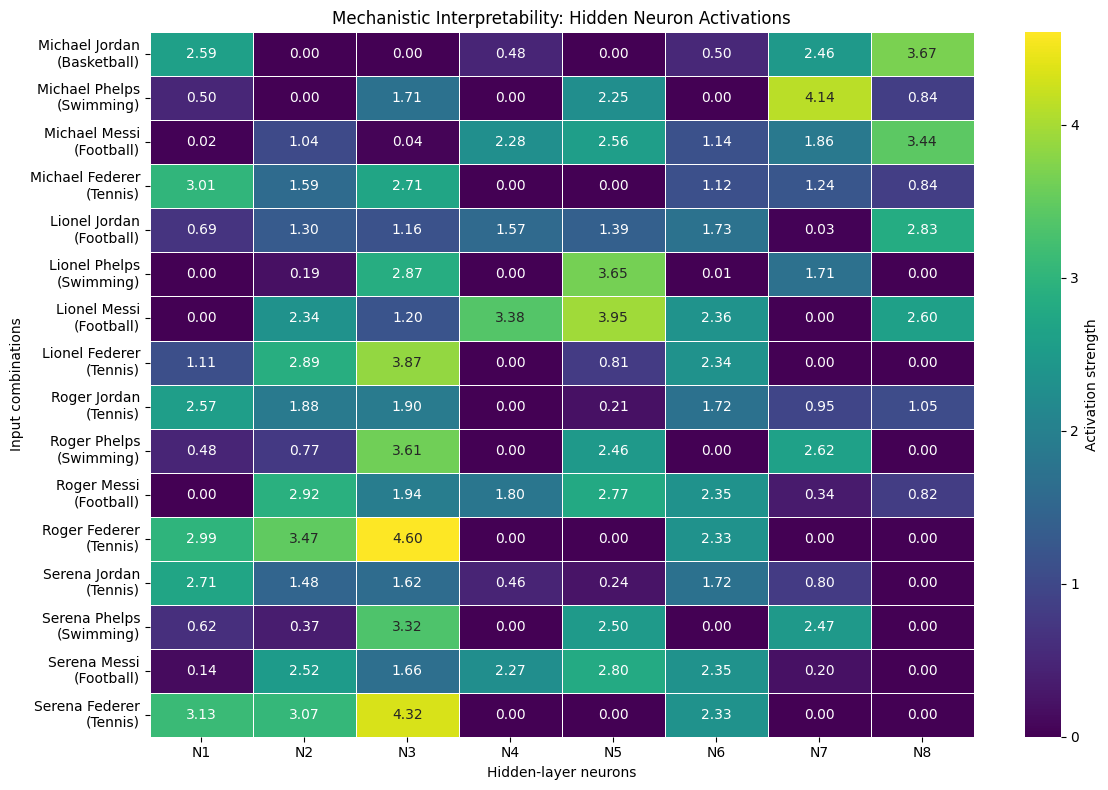

Saved visualization as activation_heatmap.png


In [46]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Get hidden-layer activations for all 16 inputs
model.eval()

with torch.no_grad():
    activations = model.get_activations(X).cpu().numpy()

# Create readable input labels
labels = [
    f"{first} {last}\n({sport})"
    for (first, last), sport in sport_data.items()
]

# Build a table: rows = inputs, columns = neurons
df = pd.DataFrame(
    activations,
    index=labels,
    columns=[f"N{i+1}" for i in range(activations.shape[1])]
)

# Plot the activation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    linewidths=0.5,
    cbar_kws={"label": "Activation strength"}
)

plt.title("Mechanistic Interpretability: Hidden Neuron Activations")
plt.xlabel("Hidden-layer neurons")
plt.ylabel("Input combinations")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("activation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved visualization as activation_heatmap.png")


Mixed behaviour of N8 : Verdict: **inconclusive**. We have evidence of a mixed activation pattern, but not proof of polysemanticity."

**Conclusion**:

The experiment demonstrated how hidden-layer activations can be extracted and analyzed to investigate the internal behavior of a neural network. N8 exhibited varying activation strengths across different name combinations, suggesting that its behavior depends on patterns in the input features. However, these observations alone were insufficient to establish polysemanticity conclusively. The experiment provided a practical introduction to neuron activations, feature specialization, and the fundamental principles of mechanistic interpretability.